# 5장 3강: 배깅 vs 부스팅 선택과 모델 해석(SHAP)

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 부스팅을 비교하고, SHAP으로 앙상블 모델의 예측 근거를 해석합니다.

- Random Forest와 XGBoost의 구조적 차이를 비교합니다.
- 성능과 학습 시간을 확인하여 상황에 맞는 모델 선택 기준을 정리합니다.
- Feature Importance의 특징과 한계를 확인합니다.
- TreeSHAP을 이용해 모델 전체의 **전역 해석**을 수행합니다.
- 특정 주택 한 건의 예측을 **지역 해석**합니다.
- SHAP 값의 부호를 이용하여 각 특성이 예측값을 올렸는지 내렸는지 설명합니다.

> 이 실습에서는 5장 3강 교안에 나온 배깅/부스팅 비교, Feature Importance, SHAP 전역·지역 해석 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- scikit-learn
- xgboost
- shap
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 숫자형 특성과 `SalePrice`를 선택합니다.
3. Train / Test 데이터로 분리합니다.
4. Random Forest와 XGBoost를 같은 데이터에서 비교합니다.
5. SHAP은 XGBoost 모델을 대상으로 확인합니다.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

Train 크기: (1168, 12)
Test 크기: (292, 12)

[결측치]


c:\Users\tae37\Desktop\실습\ML2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


---

# 필수 1. 배깅과 부스팅 비교 및 선택

## 문제 1. Random Forest와 XGBoost를 비교하세요.

### 요구사항

다음 두 모델을 사용합니다.

```python
RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
```

각 모델에 대해 다음을 확인합니다.

1. Train 데이터로 학습합니다.
2. 학습 시간을 측정합니다.
3. Test 데이터를 예측합니다.
4. Test RMSE를 계산합니다.
5. Test R²를 계산합니다.
6. 결과를 하나의 DataFrame으로 정리합니다.

### 확인 포인트

- Random Forest가 배깅 계열이라는 점을 이해했는가?
- XGBoost가 부스팅 계열이라는 점을 이해했는가?
- 성능뿐 아니라 학습 시간도 함께 확인했는가?

In [2]:
comparison_models = {
 'Random Forest':RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=1),
 'XGBoost':XGBRegressor(n_estimators=200,learning_rate=.05,max_depth=3,random_state=42,n_jobs=1)}
comparison_rows = []
for name,model in comparison_models.items():
    start = time.perf_counter(); model.fit(X_train,y_train); seconds = time.perf_counter()-start
    pred = model.predict(X_test)
    comparison_rows.append({'model':name,'fit_seconds':seconds,'test_rmse':np.sqrt(mean_squared_error(y_test,pred)),'test_r2':r2_score(y_test,pred)})
comparison_df = pd.DataFrame(comparison_rows); display(comparison_df)
xgb_model = comparison_models['XGBoost']

,model,fit_seconds,test_rmse,test_r2
0,Random Forest,0.509658,29206.646630,0.888789
1,XGBoost,0.121128,28405.320065,0.894807


### Q1. Random Forest와 XGBoost의 학습 방식은 어떻게 다른가요?

**답변:**  
Random Forest는 부트스트랩 표본에서 나무들을 독립적으로 학습하고 예측을 평균냅니다. XGBoost는 이전 예측의 손실 기울기를 보완하는 나무를 순차적으로 추가합니다. 두 방식 모두 학습 내부의 일부 계산은 병렬화할 수 있습니다.

### Q2. 다음 상황에서 어떤 방식을 우선 후보로 생각할 수 있는지 작성하세요.

1. 빠르게 베이스라인을 만들고 싶고 튜닝 여력이 적음
2. 시간을 들여 예측 성능을 더 끌어올리고 싶음
3. 노이즈가 많아 과적합 위험을 조심해야 함

**답변:**  
1. 베이스라인·튜닝 여력 부족: Random Forest를 우선 고려합니다.
2. 튜닝을 통해 성능을 더 높이고 싶음: XGBoost 같은 부스팅을 우선 후보로 둡니다.
3. 노이즈가 많음: 평균화하는 Random Forest를 시작점으로 고려하고 깊이·잎 크기를 제한합니다. 부스팅도 규제와 Early Stopping으로 사용할 수 있습니다.

---

# 필수 2. Feature Importance와 SHAP 전역 해석

## 문제 1. XGBoost의 Feature Importance를 확인하세요.

### 요구사항

1. 필수 1에서 학습한 XGBoost 모델을 사용합니다.
2. `feature_importances_`를 이용합니다.
3. 특성명과 중요도를 DataFrame으로 만듭니다.
4. 중요도가 높은 순서대로 정렬합니다.
5. 막대그래프로 표시합니다.

### 확인 포인트

- 어떤 특성이 모델 전체에서 중요하게 사용되었는지 확인했는가?
- 중요도의 크기는 알 수 있지만 방향은 알 수 없다는 점을 이해했는가?

,feature,importance
0,OverallQual,0.466007
2,GarageCars,0.131052
1,GrLivArea,0.086469
5,1stFlrSF,0.061165
7,FullBath,0.046529
6,2ndFlrSF,0.042468
4,TotalBsmtSF,0.041869
11,Fireplaces,0.040955
10,YearRemodAdd,0.034265
9,YearBuilt,0.027039


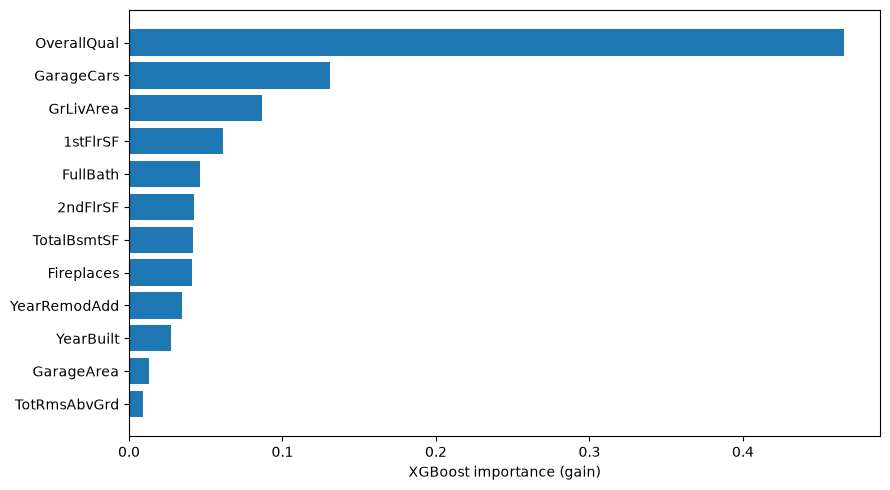

In [3]:
importance_df = pd.DataFrame({'feature':features,'importance':xgb_model.feature_importances_}).sort_values('importance',ascending=False)
display(importance_df)
plt.figure(figsize=(9,5)); plt.barh(importance_df['feature'][::-1],importance_df['importance'][::-1])
plt.xlabel('XGBoost importance (gain)'); plt.tight_layout(); plt.show()

### Q3. Feature Importance만으로는 알기 어려운 정보는 무엇인가요?

**답변:**  
전역 중요도만으로는 해당 특성이 특정 주택의 예측을 올렸는지 내렸는지, 얼마나 기여했는지 알기 어렵습니다. 상관 특성 간 중요도 분배와 분할 방식의 편향도 있어 인과적 영향으로 해석하면 안 됩니다.

## 문제 2. TreeSHAP으로 전역 중요도를 확인하세요.

### 요구사항

1. `shap.TreeExplainer()`에 XGBoost 모델을 전달합니다.
2. Test 데이터의 SHAP 값을 계산합니다.
3. `shap.plots.bar()`로 전역 중요도를 확인합니다.
4. SHAP 절댓값의 평균도 계산하여 특성별 중요도를 DataFrame으로 정리합니다.
5. 상위 특성을 확인합니다.

### 확인 포인트

- SHAP은 각 특성이 예측값에 기여한 정도를 계산한다는 점을 이해했는가?
- 전역 SHAP에서는 여러 샘플의 기여도 크기를 종합해 전체 중요도를 볼 수 있는가?

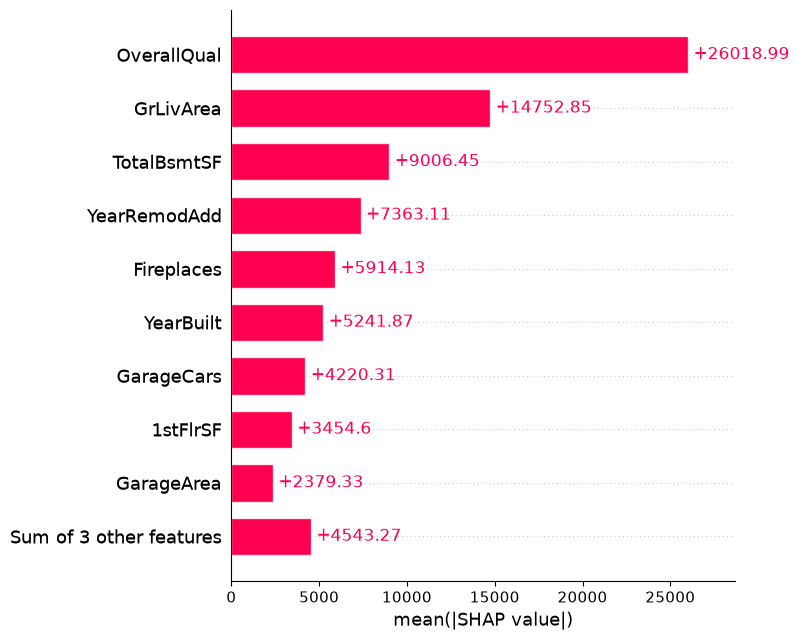

,feature,mean_abs_shap
0,OverallQual,26018.992188
1,GrLivArea,14752.852539
4,TotalBsmtSF,9006.452148
10,YearRemodAdd,7363.110352
11,Fireplaces,5914.131348
9,YearBuilt,5241.869141
2,GarageCars,4220.305664
5,1stFlrSF,3454.599609
3,GarageArea,2379.325684
6,2ndFlrSF,2307.338867


Test SHAP은 필수 실습의 설명용이며 과제의 특성 선택에는 사용하지 않습니다.


In [6]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)
shap.plots.bar(shap_values,show=False); plt.tight_layout(); plt.show()
shap_importance_df = pd.DataFrame({'feature':features,'mean_abs_shap':np.abs(shap_values.values).mean(axis=0)}).sort_values('mean_abs_shap',ascending=False)
display(shap_importance_df)
print('Test SHAP은 필수 실습의 설명용이며 과제의 특성 선택에는 사용하지 않습니다.')

### Q4. Feature Importance와 SHAP의 가장 큰 차이는 무엇인가요?

**답변:**  
Feature Importance는 분할의 손실 감소 같은 모델 내부 통계를 종합하고, SHAP은 기준값 대비 개별 예측에 대한 특성별 기여도를 배분합니다. SHAP의 부호는 방향을, 절댓값 평균은 전역 기여 크기를 보여 줍니다. 다만 전역 SHAP 막대그래프 자체는 방향을 지우며, SHAP도 인과 관계를 보장하지 않습니다.

---
# 과제 1. 모델 비교·SHAP 해석과 특성 선택 전후 검증

## 배경
주택 가격 예측 모델을 성능과 학습 시간으로 비교하고, SHAP으로 예측 근거를 설명합니다. 이어서 중요한 특성을 선택했을 때 검증 성능이 어떻게 달라지는지 확인합니다.

> 필수 1·2는 연습용입니다. 아래 과제의 비교표·해석·코드를 제출하세요. 준비 단계의 `X_train`, `y_train`을 사용하되 과제용 모델을 새로 학습합니다. Test 결과로 모델이나 특성을 선택하지 않도록, Train 안에서 Validation을 분리합니다. 개별 주택 해석 대상도 Validation의 첫 번째 주택으로 맞춥니다.

## 요구사항

### 1. 같은 조건에서 모델 비교
1. `X_train`, `y_train`을 Train_sub / Validation으로 나누세요(`test_size=0.2`, `random_state=42`). 결측값이 있으면 Train_sub에서 구한 중앙값으로 두 데이터를 채우세요.
2. Random Forest(`n_estimators=200`)와 XGBoost(`n_estimators=200`, `learning_rate=0.05`, `max_depth=3`)를 같은 Train_sub에서 학습하세요. 두 모델 모두 `random_state=42`, `n_jobs=1`로 설정하세요.
3. 각 모델의 **fit에 걸린 시간**, Train_sub RMSE, Validation RMSE와 R²를 `model_comparison`으로 정리하세요. 시간은 같은 환경에서 측정하며, 한 번의 측정만으로 일반적인 속도 우열을 단정하지 마세요.
4. 예측 오차, 학습 시간, Train/Validation 오차 차이와 운영 목적을 근거로 우선 후보를 선택하세요. 모델 선택 결과와 관계없이 다음 해석은 XGBoost로 수행합니다.

### 2. Feature Importance와 SHAP 전역·지역 해석
5. 과제용 XGBoost의 `feature_importances_`와 **Train_sub의 평균 절댓값 SHAP**을 각각 순위로 정리하여 `importance_comparison`으로 비교하세요. 전역 SHAP 막대그래프도 제출하세요.
6. Validation의 첫 번째 주택의 실제 가격·예측가격을 확인하고 SHAP waterfall plot을 그리세요.
7. 해당 주택의 절댓값 SHAP 상위 5개 특성·특성값·SHAP 값을 `local_top5`로 정리하세요. 양수·음수의 의미를 설명하고 기준값 + 모든 SHAP 값의 합이 예측값과 거의 같은지 확인하세요.
8. 두 전역 중요도 산출 원리와 한계를 비교하고, 전역 순위와 개별 주택의 기여도가 다른 이유를 설명하세요.

### 3. 중요도에 근거한 특성 선택 및 검증
9. Train_sub의 평균 절댓값 SHAP이 높은 **상위 6개 특성**을 선택하세요. 특성 선택은 이번 과제의 특성 개선 시도입니다. 개수는 비교 결과를 보기 전에 6개로 고정합니다.
10. 선택한 특성만 사용하여 동일한 XGBoost 설정으로 다시 학습하세요. 기존 모델과 동일한 Train_sub / Validation 행을 사용하고, 특성 이외의 조건은 유지하세요.
11. 전체 특성 모델과 선택 특성 모델의 특성 수·학습 시간·Train RMSE·Validation RMSE·Validation R²를 `feature_comparison`으로 비교하세요. `기존 Validation RMSE - 선택 후 Validation RMSE`와 기존 대비 개선율(%)을 계산하세요.
12. 개선 여부와 채택 여부를 수치로 설명하세요. 성능이 나빠져도 원인 가능성과 한계를 타당하게 설명하면 됩니다. 검증 결과를 반복 확인하며 특성을 바꾸지 말고, 최종 일반화 성능 확인에는 별도 Test 평가가 필요함을 밝히세요.

## 해석 질문

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.

## 제출물 / 확인 포인트
- `model_comparison`, `importance_comparison`, 전역 SHAP 그래프
- 개별 주택의 실제값·예측값·waterfall plot·`local_top5`·SHAP 합 검증
- 선택한 6개 특성, `feature_comparison`, RMSE 차이와 개선율
- 계산 코드와 Q5~Q9 답변
- 동일한 검증 조건 유지, SHAP의 방향·전역/지역 구분, 관측한 개선 여부와 해석의 한계

In [10]:
X_train_sub,X_validation,y_train_sub,y_validation = train_test_split(X_train,y_train,test_size=.2,random_state=42)
train_medians = X_train_sub.median()
X_train_sub = X_train_sub.fillna(train_medians)
X_validation = X_validation.fillna(train_medians)
task_models = {
 'Random Forest':RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=1),
 'XGBoost':XGBRegressor(n_estimators=200,learning_rate=.05,max_depth=3,random_state=42,n_jobs=1)}
task_rows = []
for name,model in task_models.items():
    start = time.perf_counter(); model.fit(X_train_sub,y_train_sub); seconds = time.perf_counter()-start
    task_rows.append({'model':name,'fit_seconds':seconds,
        'train_rmse':np.sqrt(mean_squared_error(y_train_sub,model.predict(X_train_sub))),
        'validation_rmse':np.sqrt(mean_squared_error(y_validation,model.predict(X_validation))),
        'validation_r2':r2_score(y_validation,model.predict(X_validation))})
model_comparison = pd.DataFrame(task_rows); display(model_comparison)
task_xgb = task_models['XGBoost']
preferred_model = model_comparison.loc[model_comparison['validation_rmse'].idxmin(),'model']
print('가격 예측 오차를 우선한 후보:',preferred_model)

,model,fit_seconds,train_rmse,validation_rmse,validation_r2
0,Random Forest,0.394726,12367.658293,29317.762180,0.867024
1,XGBoost,0.029884,19116.641546,27436.846466,0.883539


가격 예측 오차를 우선한 후보: XGBoost


,feature,gain,mean_abs_shap,gain_rank,shap_rank
0,OverallQual,0.427782,25416.365234,1,1
1,GrLivArea,0.078942,13777.564453,3,2
4,TotalBsmtSF,0.045537,9604.813477,6,3
10,YearRemodAdd,0.025395,7255.513184,9,4
11,Fireplaces,0.045971,6242.651367,5,5
9,YearBuilt,0.034376,6187.059570,7,6
2,GarageCars,0.205156,3490.014404,2,7
5,1stFlrSF,0.050895,3446.147461,4,8
3,GarageArea,0.016150,2788.530762,11,9
6,2ndFlrSF,0.033605,2005.598633,8,10


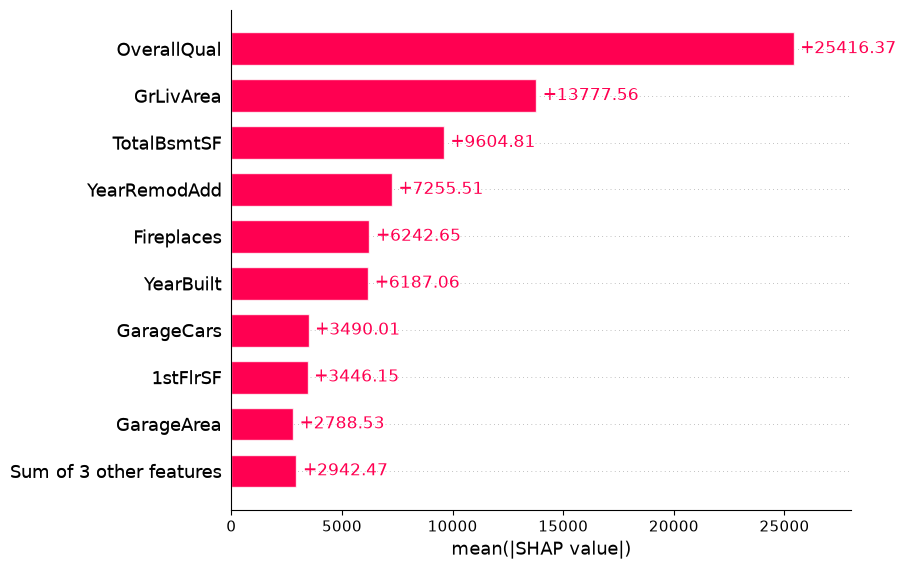

실제 가격: 140000.0 예측 가격: 149904.421875
기준값 + SHAP 합: 149904.390625 차이: -0.03125


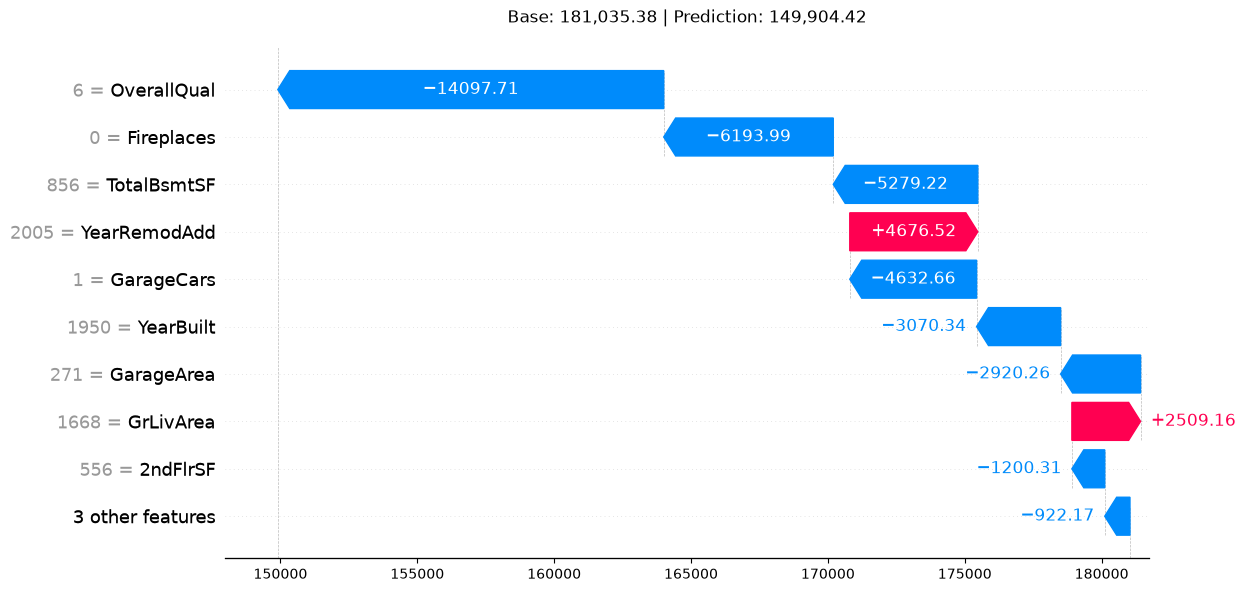

,feature,feature_value,shap_value
0,OverallQual,6,-14097.710938
11,Fireplaces,0,-6193.989258
4,TotalBsmtSF,856,-5279.219727
10,YearRemodAdd,2005,4676.523438
2,GarageCars,1,-4632.663086


In [11]:
task_explainer = shap.TreeExplainer(task_xgb)
train_shap = task_explainer(X_train_sub)
mean_abs_shap = np.abs(train_shap.values).mean(axis=0)
importance_comparison = pd.DataFrame({'feature':features,'gain':task_xgb.feature_importances_,'mean_abs_shap':mean_abs_shap})
importance_comparison['gain_rank'] = importance_comparison['gain'].rank(ascending=False,method='min').astype(int)
importance_comparison['shap_rank'] = importance_comparison['mean_abs_shap'].rank(ascending=False,method='min').astype(int)
importance_comparison = importance_comparison.sort_values('shap_rank')
display(importance_comparison)
shap.plots.bar(train_shap,show=False); plt.show()
local_shap = task_explainer(X_validation.iloc[[0]])
local_prediction = float(task_xgb.predict(X_validation.iloc[[0]])[0])
local_actual = float(y_validation.iloc[0])
local_base = float(local_shap.base_values[0])
local_reconstructed = float(local_base+local_shap.values[0].sum())
print('실제 가격:',local_actual,'예측 가격:',local_prediction)
print('기준값 + SHAP 합:',local_reconstructed,'차이:',local_reconstructed-local_prediction)
assert np.isclose(local_reconstructed,local_prediction,rtol=1e-5,atol=1)
shap.plots.waterfall(local_shap[0],show=False)
plt.gcf().set_size_inches(14,7)
plt.gcf().subplots_adjust(left=.30,right=.96,bottom=.15,top=.88)
for ax in plt.gcf().axes:
    ax.tick_params(axis='x',labelsize=10)
for ax in plt.gcf().axes[1:]:
    ax.set_xticks([])
    ax.set_xlabel('')
plt.gcf().axes[0].set_title(f'Base: {local_base:,.2f} | Prediction: {local_prediction:,.2f}',pad=18)
plt.show()
local_details = pd.DataFrame({'feature':features,'feature_value':X_validation.iloc[0].to_numpy(),
    'shap_value':local_shap.values[0],'abs_shap':np.abs(local_shap.values[0])})
local_top5 = local_details.nlargest(5,'abs_shap').drop(columns='abs_shap')
display(local_top5)

In [12]:
selected_features = importance_comparison.head(6)['feature'].tolist()
print('Train_sub SHAP 상위 6개:',selected_features)
selected_model = XGBRegressor(n_estimators=200,learning_rate=.05,max_depth=3,random_state=42,n_jobs=1)
start = time.perf_counter(); selected_model.fit(X_train_sub[selected_features],y_train_sub); selected_seconds = time.perf_counter()-start
selected_train_rmse = np.sqrt(mean_squared_error(y_train_sub,selected_model.predict(X_train_sub[selected_features])))
selected_valid_prediction = selected_model.predict(X_validation[selected_features])
selected_valid_rmse = np.sqrt(mean_squared_error(y_validation,selected_valid_prediction))
full_row = model_comparison.set_index('model').loc['XGBoost']
feature_comparison = pd.DataFrame([
 {'model':'All features','feature_count':len(features),'fit_seconds':full_row['fit_seconds'],
  'train_rmse':full_row['train_rmse'],'validation_rmse':full_row['validation_rmse'],'validation_r2':full_row['validation_r2']},
 {'model':'Top 6 SHAP','feature_count':6,'fit_seconds':selected_seconds,'train_rmse':selected_train_rmse,
  'validation_rmse':selected_valid_rmse,'validation_r2':r2_score(y_validation,selected_valid_prediction)}])
rmse_improvement = float(full_row['validation_rmse']-selected_valid_rmse)
improvement_percent = float(100*rmse_improvement/full_row['validation_rmse'])
display(feature_comparison)
print('RMSE 차이(기존−선택):',rmse_improvement,'개선율(%):',improvement_percent)
print('채택 제안:', '상위 6개 모델' if rmse_improvement>0 else '전체 특성 모델 유지')
print('Test를 사용하지 않은 검증 결과입니다. 반복적인 특성 변경 없이 판단하며 최종 일반화 확인에는 별도 Test 평가가 필요합니다.')

Train_sub SHAP 상위 6개: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt']


,model,feature_count,fit_seconds,train_rmse,validation_rmse,validation_r2
0,All features,12,0.029884,19116.641546,27436.846466,0.883539
1,Top 6 SHAP,6,0.021546,20282.480322,30029.857143,0.860486


RMSE 차이(기존−선택): -2593.010676496513 개선율(%): -9.450833497602677
채택 제안: 전체 특성 모델 유지
Test를 사용하지 않은 검증 결과입니다. 반복적인 특성 변경 없이 판단하며 최종 일반화 확인에는 별도 Test 평가가 필요합니다.


## Q5~Q9 답변

**Q5.** 반드시 그렇지는 않습니다. 전역 순위는 여러 Train_sub 주택의 절댓값 기여를 평균낸 값이고, 지역 기여는 해당 주택의 특성값과 상호작용에 따라 달라집니다.

**Q6.** 양수는 기준 예측보다 가격을 올리는 기여, 음수는 낮추는 기여입니다.  

**Q7.** 가격 예측 오차를 우선해 XGBoost를 후보로 선택했습니다. Validation RMSE=27,436.85, R²=0.8835, fit 시간=0.073초이며 Train RMSE=19,116.64입니다. Random Forest: Train RMSE=12,367.66, Validation RMSE=29,317.76, fit=1.248초; XGBoost: Train RMSE=19,116.64, Validation RMSE=27,436.85, fit=0.073초. Train과 Validation의 오차 차이는 과적합 신호를 점검하는 근거지만 단일 분할만으로 원인을 확정하지 않습니다. 한 번의 소규모 측정은 일반적인 속도 순위가 아닙니다.

**Q8.** 여기의 XGBoost 중요도는 특성 분할의 평균 gain을 정규화한 값이고, SHAP 전역 중요도는 Train_sub의 특성별 평균 절댓값 기여입니다. gain 상위 5개는 OverallQual, GarageCars, GrLivArea, 1stFlrSF, Fireplaces, SHAP 상위 5개는 OverallQual, GrLivArea, TotalBsmtSF, YearRemodAdd, Fireplaces입니다. 둘은 산출 기준과 사용 빈도·분할 효과의 반영 방식이 달라 순위가 다를 수 있습니다. 상관 특성의 기여 배분과 데이터 분포에 의존하며 인과적 해석은 불가합니다.

**Q9.** 사전에 고정한 상위 6개는 OverallQual, GrLivArea, TotalBsmtSF, YearRemodAdd, Fireplaces, YearBuilt입니다. 전체 모델 Validation RMSE=27,436.85, 선택 모델=30,029.86, 기존−선택=-2,593.01, 개선율=-9.45%입니다. 검증 오차가 증가했으므로 전체 특성 모델을 유지하겠습니다. 일부 특성의 상호보완 정보가 제거되었을 수 있습니다. 단일 Validation과 SHAP 방식에 의존한 비교이므로 일반적인 개선을 보장하지 않습니다. 같은 Validation을 보며 특성을 반복 변경하지 않았으며 최종 확인은 별도 Test로 해야 합니다.


---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 배깅과 부스팅의 학습 방식 차이는 무엇인가요?  
-> 배깅은 독립 학습·평균화, 부스팅은 순차적 오류 보완입니다.

2. 배깅과 부스팅은 각각 편향과 분산 중 무엇을 줄이는 데 초점을 두나요?  
-> 일반적으로 배깅은 분산, 부스팅은 편향 감소에 초점을 둡니다.

3. 튜닝 여력이 부족한 상황에서는 어떤 모델군을 먼저 고려할 수 있나요?  
-> Random Forest 같은 배깅 계열입니다.

4. Feature Importance의 가장 큰 한계는 무엇인가요?  
-> 방향과 개별 예측의 기여를 설명하지 못하고 인과성도 알 수 없습니다.

5. SHAP의 전역 해석과 지역 해석은 무엇이 다른가요?  
-> 전역은 여러 샘플의 기여를 종합하고 지역은 특정 샘플의 예측을 설명합니다.

6. SHAP 값의 양수와 음수는 무엇을 의미하나요?  
-> 기준값보다 예측을 올리거나 내리는 기여입니다.